Notebook 3: Classical baselines

Imports and data

In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.1.2
[notice] To update, run: C:\Users\Admin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import (
    TfidfVectorizer
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
from sklearn.pipeline import Pipeline

SEED = 42

PROJECT_ROOT = Path("..")
PROCESSED_DIR = PROJECT_ROOT / "processed_data"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"

for directory in [
    MODELS_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(
    PROCESSED_DIR / "train_utterances.csv"
)

validation_df = pd.read_csv(
    PROCESSED_DIR / "validation_utterances.csv"
)

test_df = pd.read_csv(
    PROCESSED_DIR / "test_utterances.csv"
)

Evaluation Function

In [4]:
LABEL_IDS = [0, 1, 2, 3, 4, 5, 6]

LABEL_NAMES = [
    "neutral",
    "anger",
    "disgust",
    "fear",
    "happiness",
    "sadness",
    "surprise"
]


def evaluate_model(
    y_true,
    y_pred,
    model_name,
    output_directory=None
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    emotional_mask = y_true != 0

    results = {
        "model": model_name,
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "micro_f1_all": f1_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0
        ),
        "micro_f1_excluding_neutral": (
            f1_score(
                y_true[emotional_mask],
                y_pred[emotional_mask],
                average="micro",
                zero_division=0
            )
            if emotional_mask.any()
            else np.nan
        )
    }

    report = classification_report(
        y_true,
        y_pred,
        labels=LABEL_IDS,
        target_names=LABEL_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report
    ).transpose()

    print(pd.Series(results))
    display(report_df.round(4))

    if output_directory is not None:
        safe_name = (
            model_name.lower()
            .replace(" ", "_")
            .replace("+", "plus")
            .replace("-", "_")
        )

        report_df.to_csv(
            Path(output_directory)
            / f"{safe_name}_report.csv"
        )

    return results, report_df

Majority Baseline

In [5]:
X_train_dummy = np.zeros(
    shape=(len(train_df), 1)
)

X_validation_dummy = np.zeros(
    shape=(len(validation_df), 1)
)

y_train = train_df[
    "emotion_label"
].to_numpy()

y_validation = validation_df[
    "emotion_label"
].to_numpy()

majority_model = DummyClassifier(
    strategy="most_frequent"
)

majority_model.fit(
    X_train_dummy,
    y_train
)

majority_predictions = majority_model.predict(
    X_validation_dummy
)

majority_results, majority_report = (
    evaluate_model(
        y_validation,
        majority_predictions,
        model_name="Majority baseline",
        output_directory=TABLES_DIR
    )
)

model                         Majority baseline
accuracy                               0.880902
macro_f1                               0.133812
weighted_f1                            0.825124
micro_f1_all                           0.880902
micro_f1_excluding_neutral                  0.0
dtype: object


,precision,recall,f1-score,support
neutral,0.8809,1.0000,0.9367,7108.0000
anger,0.0000,0.0000,0.0000,77.0000
disgust,0.0000,0.0000,0.0000,3.0000
fear,0.0000,0.0000,0.0000,11.0000
happiness,0.0000,0.0000,0.0000,684.0000
sadness,0.0000,0.0000,0.0000,79.0000
surprise,0.0000,0.0000,0.0000,107.0000
accuracy,0.8809,0.8809,0.8809,0.8809
macro avg,0.1258,0.1429,0.1338,8069.0000
weighted avg,0.7760,0.8809,0.8251,8069.0000


TF-IDF model function

In [6]:
def create_tfidf_model():
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                strip_accents="unicode",
                analyzer="word",
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.98,
                max_features=60000,
                sublinear_tf=True
            )
        ),
        (
            "classifier",
            LogisticRegression(
                C=2.0,
                max_iter=3000,
                class_weight="balanced",
                solver="liblinear",
                random_state=SEED
            )
        )
    ])

compare all context settings fairly

In [7]:
TEXT_EXPERIMENTS = {
    "no_context": "text_no_context",
    "previous_1": "text_context_1",
    "previous_3": "text_context_3",
    "full_context": "text_full_context",
    "shuffled_context": "text_shuffled_context",
    "unrelated_context": "text_unrelated_context"
}

tfidf_models = {}
tfidf_results = []
tfidf_predictions = {}

for experiment_name, text_column in (
    TEXT_EXPERIMENTS.items()
):
    print(
        "\n",
        "=" * 70,
        f"\nExperiment: {experiment_name}\n"
    )

    model = create_tfidf_model()

    model.fit(
        train_df[text_column].fillna(""),
        y_train
    )

    predictions = model.predict(
        validation_df[text_column].fillna("")
    )

    metrics, _ = evaluate_model(
        y_validation,
        predictions,
        model_name=f"TF-IDF {experiment_name}",
        output_directory=TABLES_DIR
    )

    metrics["context_setting"] = (
        experiment_name
    )

    tfidf_models[experiment_name] = model
    tfidf_predictions[experiment_name] = (
        predictions
    )
    tfidf_results.append(metrics)

tfidf_results_df = pd.DataFrame(
    tfidf_results
)

display(
    tfidf_results_df.sort_values(
        "macro_f1",
        ascending=False
    )
)


Experiment: no_context



C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


model                         TF-IDF no_context
accuracy                               0.881398
macro_f1                               0.400326
weighted_f1                            0.886737
micro_f1_all                           0.881398
micro_f1_excluding_neutral             0.592092
dtype: object


,precision,recall,f1-score,support
neutral,0.9502,0.9205,0.9351,7108.0000
anger,0.4444,0.3117,0.3664,77.0000
disgust,0.0000,0.0000,0.0000,3.0000
fear,0.3333,0.0909,0.1429,11.0000
happiness,0.5309,0.6784,0.5956,684.0000
sadness,0.3241,0.4430,0.3743,79.0000
surprise,0.3600,0.4206,0.3879,107.0000
accuracy,0.8814,0.8814,0.8814,0.8814
macro avg,0.4204,0.4093,0.4003,8069.0000
weighted avg,0.8947,0.8814,0.8867,8069.0000



Experiment: previous_1



C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


... (15 outputs left out)

C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


model                         TF-IDF unrelated_context
accuracy                                      0.844219
macro_f1                                      0.230097
weighted_f1                                    0.83772
micro_f1_all                                  0.844219
micro_f1_excluding_neutral                     0.24974
dtype: object


,precision,recall,f1-score,support
neutral,0.9052,0.9246,0.9148,7108.0000
anger,0.1944,0.0909,0.1239,77.0000
disgust,0.0000,0.0000,0.0000,3.0000
fear,0.0000,0.0000,0.0000,11.0000
happiness,0.3493,0.3085,0.3276,684.0000
sadness,0.1061,0.0886,0.0966,79.0000
surprise,0.1562,0.1402,0.1478,107.0000
accuracy,0.8442,0.8442,0.8442,0.8442
macro avg,0.2445,0.2218,0.2301,8069.0000
weighted avg,0.8320,0.8442,0.8377,8069.0000


,model,accuracy,macro_f1,weighted_f1,micro_f1_all,micro_f1_excluding_neutral,context_setting
0,TF-IDF no_context,0.881398,0.400326,0.886737,0.881398,0.592092,no_context
1,TF-IDF previous_1,0.869501,0.359350,0.873438,0.869501,0.511967,previous_1
2,TF-IDF previous_3,0.864295,0.339287,0.867155,0.864295,0.467222,previous_3
4,TF-IDF shuffled_context,0.862684,0.332202,0.865963,0.862684,0.466181,shuffled_context
3,TF-IDF full_context,0.855868,0.322639,0.858762,0.855868,0.418314,full_context
5,TF-IDF unrelated_context,0.844219,0.230097,0.837720,0.844219,0.249740,unrelated_context


Creating one final comparison table

In [8]:
comparison_table = pd.concat(
    [
        pd.DataFrame([{
            "model": "Majority baseline",
            "context_setting": "none",
            "accuracy": majority_results["accuracy"],
            "macro_f1": majority_results["macro_f1"],
            "weighted_f1": majority_results["weighted_f1"]
        }]),
        tfidf_results_df[
            [
                "model",
                "context_setting",
                "accuracy",
                "macro_f1",
                "weighted_f1"
            ]
        ]
    ],
    ignore_index=True
)

comparison_table = comparison_table.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

display(comparison_table.round(4))

comparison_table.to_csv(
    TABLES_DIR / "classical_model_comparison.csv",
    index=False
)

,model,context_setting,accuracy,macro_f1,weighted_f1
0,TF-IDF no_context,no_context,0.8814,0.4003,0.8867
1,TF-IDF previous_1,previous_1,0.8695,0.3593,0.8734
2,TF-IDF previous_3,previous_3,0.8643,0.3393,0.8672
3,TF-IDF shuffled_context,shuffled_context,0.8627,0.3322,0.8660
4,TF-IDF full_context,full_context,0.8559,0.3226,0.8588
5,TF-IDF unrelated_context,unrelated_context,0.8442,0.2301,0.8377
6,Majority baseline,none,0.8809,0.1338,0.8251


Automatically select the best TF-IDF model

In [11]:
best_row = tfidf_results_df.loc[
    tfidf_results_df["macro_f1"].idxmax()
]

BEST_TFIDF_SETTING = best_row["context_setting"]

print("Best TF-IDF setting:", BEST_TFIDF_SETTING)
print("Best validation Macro-F1:", round(best_row["macro_f1"], 4))
print("Accuracy:", round(best_row["accuracy"], 4))
print("Weighted-F1:", round(best_row["weighted_f1"], 4))

Best TF-IDF setting: no_context
Best validation Macro-F1: 0.4003
Accuracy: 0.8814
Weighted-F1: 0.8867


getting it's best prediction

In [12]:
best_predictions = tfidf_predictions[
    BEST_TFIDF_SETTING
]

Producing the per-class report and normalized confusion matrix

In [13]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

report = classification_report(
    y_validation,
    best_predictions,
    labels=LABEL_IDS,
    target_names=LABEL_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

report_df.to_csv(
    TABLES_DIR
    / f"best_tfidf_{BEST_TFIDF_SETTING}_report.csv"
)

,precision,recall,f1-score,support
neutral,0.9502,0.9205,0.9351,7108.0000
anger,0.4444,0.3117,0.3664,77.0000
disgust,0.0000,0.0000,0.0000,3.0000
fear,0.3333,0.0909,0.1429,11.0000
happiness,0.5309,0.6784,0.5956,684.0000
sadness,0.3241,0.4430,0.3743,79.0000
surprise,0.3600,0.4206,0.3879,107.0000
accuracy,0.8814,0.8814,0.8814,0.8814
macro avg,0.4204,0.4093,0.4003,8069.0000
weighted avg,0.8947,0.8814,0.8867,8069.0000


Normalized confusion matrix

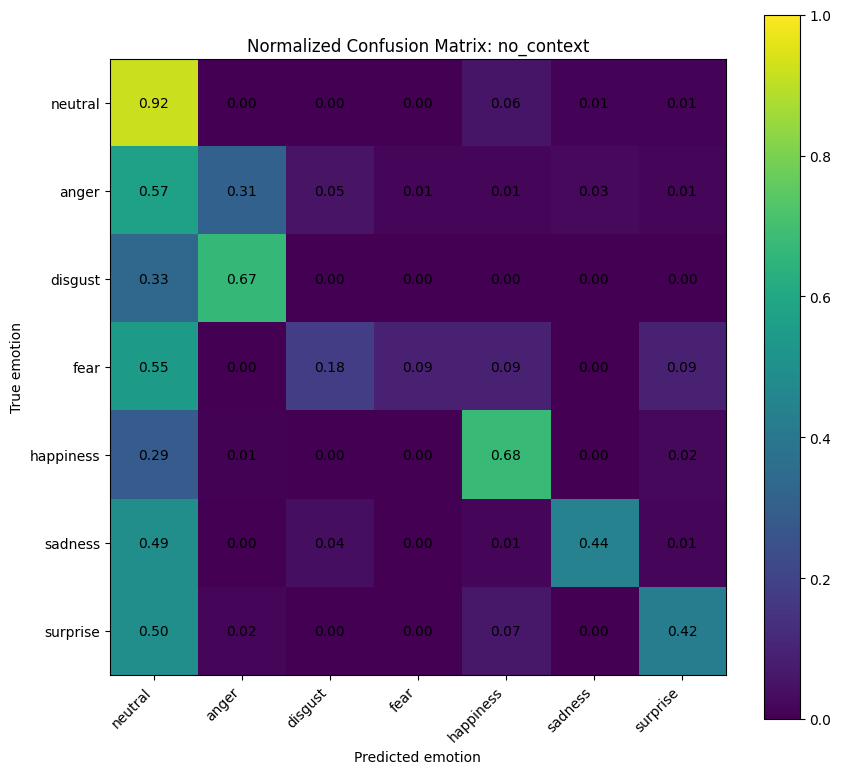

In [14]:
normalized_cm = confusion_matrix(
    y_validation,
    best_predictions,
    labels=LABEL_IDS,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(9, 8))

image = ax.imshow(
    normalized_cm,
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(LABEL_NAMES)))
ax.set_xticklabels(
    LABEL_NAMES,
    rotation=45,
    ha="right"
)

ax.set_yticks(range(len(LABEL_NAMES)))
ax.set_yticklabels(LABEL_NAMES)

for row in range(normalized_cm.shape[0]):
    for column in range(normalized_cm.shape[1]):
        ax.text(
            column,
            row,
            f"{normalized_cm[row, column]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title(
    f"Normalized Confusion Matrix: {BEST_TFIDF_SETTING}"
)

ax.set_xlabel("Predicted emotion")
ax.set_ylabel("True emotion")

fig.colorbar(image)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / f"best_tfidf_{BEST_TFIDF_SETTING}_normalized_cm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Creating a small qualitative error-analysis table

In [16]:
analysis_df = validation_df[
    [
        "dialogue_id",
        "turn_index",
        "previous_3",
        "utterance",
        "emotion_label",
        "emotion_name"
    ]
].copy()

analysis_df["predicted_label"] = best_predictions

ID_TO_LABEL = dict(zip(LABEL_IDS, LABEL_NAMES))

analysis_df["predicted_emotion"] = (
    analysis_df["predicted_label"]
    .map(ID_TO_LABEL)
)

analysis_df["correct"] = (
    analysis_df["emotion_label"]
    == analysis_df["predicted_label"]
)

error_examples = (
    analysis_df.loc[
        ~analysis_df["correct"]
    ]
    .sample(
        n=min(20, (~analysis_df["correct"]).sum()),
        random_state=42
    )
    .copy()
)

error_examples["manual_comment"] = ""

display(error_examples)

error_examples.to_csv(
    TABLES_DIR / "best_tfidf_error_examples.csv",
    index=False
)

,dialogue_id,turn_index,previous_3,utterance,emotion_label,emotion_name,predicted_label,predicted_emotion,correct,manual_comment
7021,validation_00878,4,[SPEAKER_B] Can you show me some traditional C...,Of course .,0,neutral,4,happiness,False,
4063,validation_00501,9,[SPEAKER_A] Would you please ask him to call C...,13924774026 . All right . Thanks for calling ....,0,neutral,4,happiness,False,
3101,validation_00382,12,"[SPEAKER_B] Unfortunately , I'm leaving town r...",Bye-bye .,0,neutral,4,happiness,False,
7446,validation_00927,5,[SPEAKER_A] Good . I wanna come with you . [SE...,"Wow , that's something new . Let's go ! What's...",0,neutral,4,happiness,False,
7188,validation_00897,6,"[SPEAKER_B] Well , where shall I pay the duty ...",Very well . I hope you'll enjoy your stay in C...,0,neutral,4,happiness,False,
2410,validation_00297,4,[SPEAKER_B] I feel sorry for you . It's a jung...,Thank you . I think I should also have a look ...,4,happiness,0,neutral,False,
1897,validation_00230,0,NaN,We hope that there will be no repetition of th...,1,anger,0,neutral,False,
3021,validation_00371,11,"[SPEAKER_A] Well , you're no gentleman , eithe...",What was that you just said ? Last one ... ? H...,0,neutral,6,surprise,False,
780,validation_00088,11,[SPEAKER_A] How much more ? [SEP] [SPEAKER_B] ...,We have a deal then .,4,happiness,0,neutral,False,
7672,validation_00951,9,[SPEAKER_A] You can't send this document ; it ...,Great . How much ?,0,neutral,4,happiness,False,


## Result comments

- The table shows validation examples where the model prediction was incorrect.
- Most errors are `neutral` sentences predicted as `happiness`.
- One example shows `happiness` predicted as `neutral`, and another `anger` predicted as `neutral`.
- The `correct` column is `False` for all shown rows, so this is a failure analysis subset.
- This suggests the model struggles with subtle emotional tone and often confuses neutral content with positive/happy language.

Adding one short results summary

In [17]:
no_context_row = tfidf_results_df.loc[
    tfidf_results_df["context_setting"]
    == "no_context"
].iloc[0]

best_macro_f1 = best_row["macro_f1"]
no_context_macro_f1 = no_context_row["macro_f1"]

difference = (
    best_macro_f1
    - no_context_macro_f1
)

print("RESULTS SUMMARY")
print("-" * 60)

print(
    f"The majority baseline achieved high accuracy "
    f"({majority_results['accuracy']:.4f}) but low "
    f"Macro-F1 ({majority_results['macro_f1']:.4f}), "
    "showing the effect of class imbalance."
)

print(
    f"The best TF-IDF model used '{BEST_TFIDF_SETTING}' "
    f"and achieved Macro-F1={best_macro_f1:.4f}."
)

print(
    f"Compared with TF-IDF without context, "
    f"Macro-F1 changed by {difference:+.4f}."
)

RESULTS SUMMARY
------------------------------------------------------------
The majority baseline achieved high accuracy (0.8809) but low Macro-F1 (0.1338), showing the effect of class imbalance.
The best TF-IDF model used 'no_context' and achieved Macro-F1=0.4003.
Compared with TF-IDF without context, Macro-F1 changed by +0.0000.


save model and results

In [19]:
tfidf_results_df.to_csv(
    TABLES_DIR / "tfidf_context_results.csv",
    index=False
)

for model_name, model in tfidf_models.items():
    joblib.dump(
        model,
        MODELS_DIR
        / f"tfidf_{model_name}.joblib"
    )